# Tutorial: Analysis of Coupled Rhythms (LFP–LFP and Spike–LFP)
#### Lecturer: Conrado A. Bosman

## Introduction

In this tutorial, we study how rhythmic activity is shared between signals. We will focus on:

1. **LFP–LFP coupling** (two ECoG electrodes)
   - Cross-covariance
   - Trial-averaged spectrum
   - Coherence
   - Phase difference distributions

2. **Spike–LFP coupling**
   - Spike-triggered average (STA)
   - Field-triggered average (FTA) using phase (Hilbert transform)
   - Spike–field coherence (SFC)
   - Impact of LFP amplitude and firing rate on SFC

We build directly on our previous notebooks on:
- autocovariance,
- Fourier transform and spectra,
- filtering and phase.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.io import loadmat
from scipy.signal import correlate, firwin, filtfilt, hilbert

plt.rcParams["figure.figsize"] = (8, 4)

## Part 1 – LFP–LFP Coupling (ECoG electrodes)

### Load and visualize the ECoG data

In our patient with intractable epilepsy, as a part of her clinical workup before resective surgery, numerous electrodes were implanted directly on the cortical surface. The patient collaborated in an auditory task study. The task required  the patient to listen to phonemes through a headphone and respond with a button click whenever she heard “*ba*” (among other phonemes: “*pa*” “*da*” “*ta*”). The tone presentation was repeated 100 times. We will analyze a 1s segment of two cortical electrodes sampled at 500 Hz. 
We selected two electrodes (`E1` and `E2`) from the array, and assigned a variable name.
Each variable (`E1`, `E2`) is organized as a **trials × time** matrix:
- rows = trials,
- columns = time samples.

We first visualize a single trial from both electrodes, and then use a trial-by-time image.


In [4]:
# Base directory = folder where this notebook lives
base_dir = Path().resolve()

data_file = base_dir / "chapter5_Data" / "Ch5-ECoG-1.mat"

# Load ECoG data (Chapter 5)
data_ecog = loadmat(data_file)
E1 = data_ecog["E1"]   # shape: (trials, samples)
E2 = data_ecog["E2"]
t  = data_ecog["t"].ravel()

dt = t[1] - t[0]
fs = 1.0 / dt
K  = E1.shape[0]       # number of trials
N  = E1.shape[1]       # samples per trial

print(f"E1 shape: {E1.shape}, E2 shape: {E2.shape}, dt = {dt:.4f} s, fs = {fs:.1f} Hz")

E1 shape: (100, 500), E2 shape: (100, 500), dt = 0.0020 s, fs = 500.0 Hz


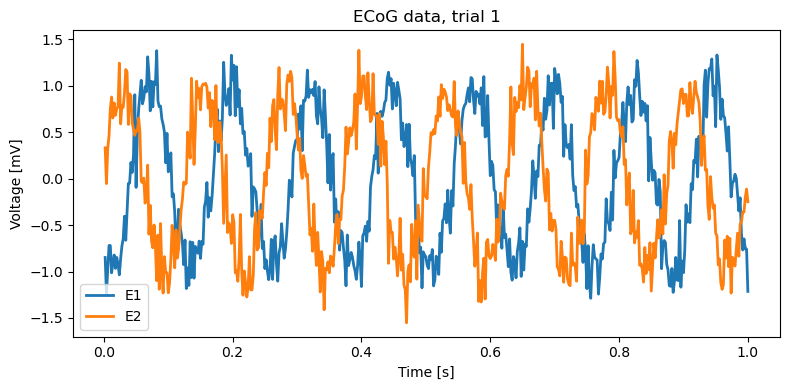

In [5]:
# Plot one trial from each electrode
trial_idx = 0

plt.figure()
plt.plot(t, E1[trial_idx, :], label="E1", linewidth=2)
plt.plot(t, E2[trial_idx, :], label="E2", linewidth=2)
plt.xlabel("Time [s]")
plt.ylabel("Voltage [mV]")
plt.title(f"ECoG data, trial {trial_idx+1}")
plt.legend()
plt.tight_layout()
plt.show()

**Task**: Change the value of the `trial_idx` variable to evaluate other trials.

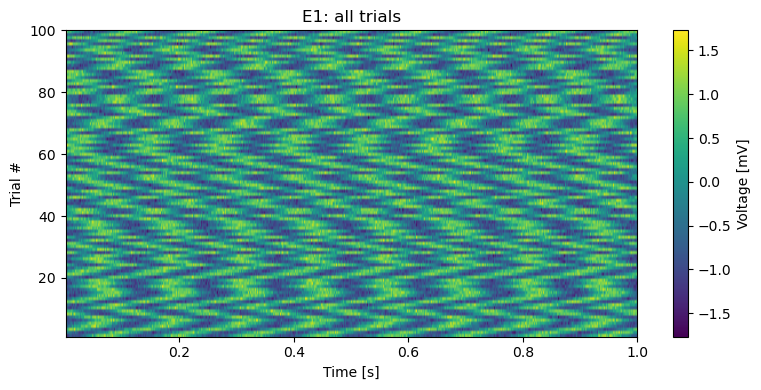

In [6]:
# Image all trials from electrode E1
plt.figure()
plt.imshow(
    E1,
    aspect="auto",
    origin="lower",
    extent=[t[0], t[-1], 1, K],
)
plt.colorbar(label="Voltage [mV]")
plt.xlabel("Time [s]")
plt.ylabel("Trial #")
plt.title("E1: all trials")
plt.tight_layout()
plt.show()

### Trial-averaged autocovariance

We recall the **trial-averaged autocovariance**:

$$
r_{xx}[L] = \frac{1}{K} \sum_{k=1}^K \frac{1}{N}
\sum_{n=1}^{N-L} (x_{n+L,k} - \bar x_k)(x_{n,k} - \bar x_k).
$$

We approximate this using `scipy.signal.correlate` with a **biased** normalization
(dividing by `N`) and then averaging across trials.


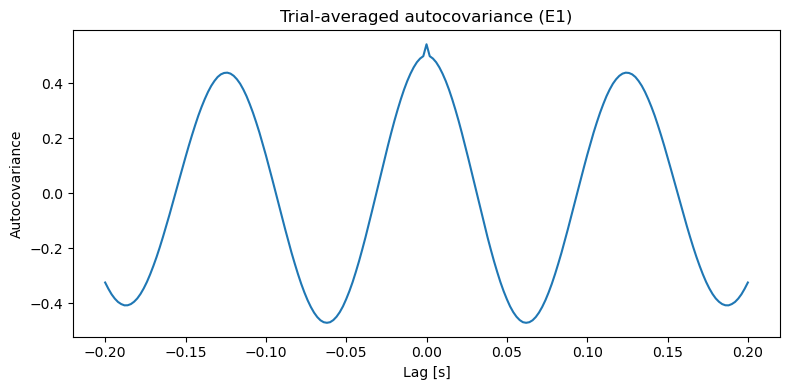

In [7]:
max_lags = 100  # +/- lags in samples
lags = np.arange(-max_lags, max_lags + 1)
lags_time = lags * dt

ac_total = np.zeros_like(lags_time, dtype=float)

for k in range(K):
    x = E1[k, :] - E1[k, :].mean()
    # full correlation, then restrict to desired lags
    ac_full = correlate(x, x, mode="full") / N
    mid = len(ac_full) // 2
    ac_slice = ac_full[mid - max_lags : mid + max_lags + 1]
    ac_total += ac_slice

ac_mean = ac_total / K

plt.figure()
plt.plot(lags_time, ac_mean)
plt.xlabel("Lag [s]")
plt.ylabel("Autocovariance")
plt.title("Trial-averaged autocovariance (E1)")
plt.tight_layout()
plt.show()

The trial-averaged autocovariance of `E1` suggests that the signalas has a strong oscillatory component. The lag of ±0.125 s corresponds to a frequency of 8 Hz $(1/0.125 = 8)$.

### Single-trial cross-covariance and trial-averaged cross-covariance

The **cross-covariance** extends autocovariance to two time series:

$$
r_{xy}[L] = \frac{1}{N} \sum_{n=1}^{N-L} (x_{n+L} - \bar x)(y_n - \bar y).
$$

A graphical representation of the cross-covariance is similar to the autocovariance (except that we anaslyze **two** time-series instead of one:

![Cross-covariance cartoon](chapter5_Data/cross-covariance.png)

We first compute it for a single trial and then average across trials.


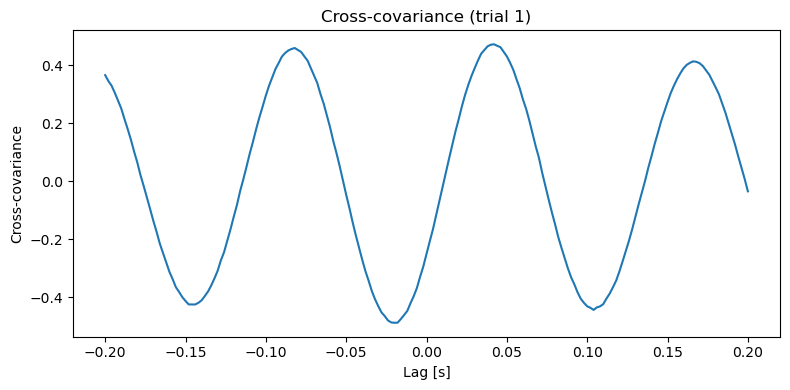

In [25]:
# Single-trial cross-covariance
x = E1[0, :] - E1[0, :].mean()
y = E2[0, :] - E2[0, :].mean()

xc_full = correlate(x, y, mode="full") / N
mid = len(xc_full) // 2
xc = xc_full[mid - max_lags : mid + max_lags + 1]

plt.figure()
plt.plot(lags_time, xc)
plt.xlabel("Lag [s]")
plt.ylabel("Cross-covariance")
plt.title("Cross-covariance (trial 1)")
plt.tight_layout()
plt.show()

Although trial 1 of `E1` and `E2` are in **anti-phase**, their cross-covariance still oscillates at the same frequency (8 Hz) because they share the same underlying rhythm; the phase shift appears as a sign reversal at lag zero and a shift in the peaks of the covariance, not as a change in frequency.

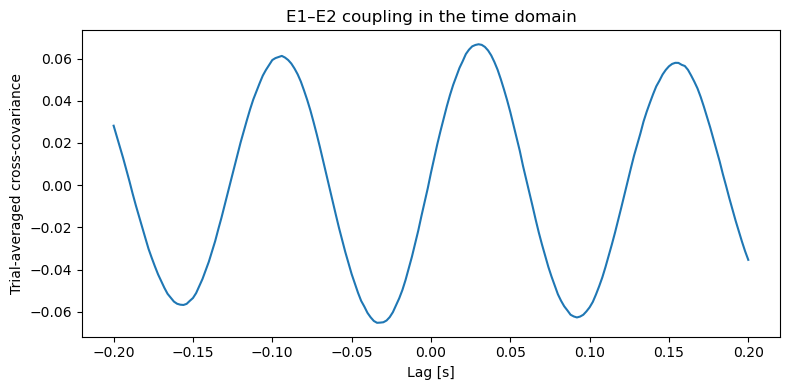

In [28]:
# Trial-averaged cross-covariance
XC = np.zeros_like(lags_time, dtype=float)

for k in range(K):
    x = E1[k, :] - E1[k, :].mean()
    y = E2[k, :] - E2[k, :].mean()
    xc_full = correlate(x, y, mode="full") / N
    mid = len(xc_full) // 2
    xc_slice = xc_full[mid - max_lags : mid + max_lags + 1]
    XC += xc_slice

XC /= K

plt.figure()
plt.plot(lags_time, XC)
plt.xlabel("Lag [s]")
#plt.ylim([-0.5,0.5])
plt.ylabel("Trial-averaged cross-covariance")
plt.title("E1–E2 coupling in the time domain")
plt.tight_layout()
plt.show()

The **single-trial cross-covariance functions are not well aligned across trials**.  
Each trial contains its own fluctuations, noise, and slight phase shifts, so the
cross-covariance curves vary considerably from one trial to the next.

When we **average** the cross-covariance across trials, these idiosyncratic,
trial-specific deviations tend to cancel out. Large positive or negative
fluctuations that appear only in individual trials do not survive the averaging
process. What remains is the **consistent structure shared across trials**:
the underlying oscillatory coupling between the two electrodes.

In other words:

- **noise and trial-specific features average out**,  
- **shared rhythmic patterns (e.g., the 8 Hz component) become clearer**,  
- and the averaged cross-covariance reveals the *true, reliable coupling*
between E1 and E2.

This is why the trial-averaged cross-covariance looks smoother and more
interpretable than the highly variable single-trial functions.

To further characterize the relationship between the two electrodes, we now move
from the time-domain description (cross-covariance) to the **spectral domain**.
Examining the power spectrum of each signal will allow us to identify their
dominant rhythmic components and determine whether they share common frequencies
that might underlie the coupling observed in the time domain.


### Trial-averaged spectrum of E1

We now compute the trial-averaged spectrum of `E1` using the same approach
as in previous notebooks: FFT per trial, conjugate multiplication, and averaging.


In [29]:
def spectrum(x, t, use_hann=True):
    """Compute one-sided power spectrum of a single trial x given time vector t."""
    dt = t[1] - t[0]
    T = len(t) * dt
    x0 = x - x.mean()

    if use_hann:
        window = np.hanning(len(x))
        xw = window * x0
    else:
        xw = x0

    xf = np.fft.rfft(xw)
    Sxx = 2 * (dt**2) / T * (xf * np.conj(xf))
    return Sxx.real

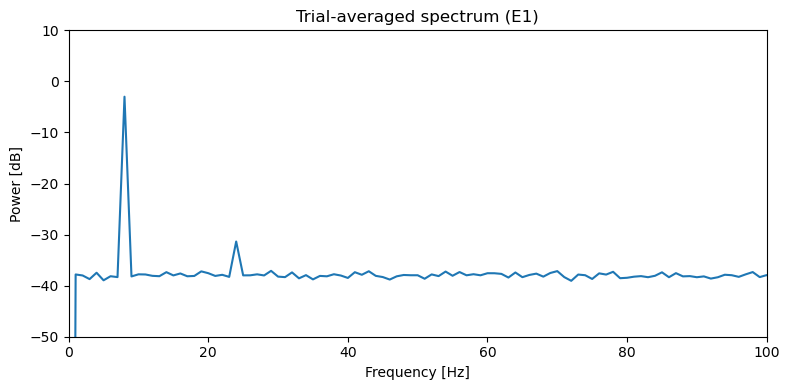

In [31]:
# Compute spectra across trials
Sxx_trials = np.array([spectrum(E1[k, :], t, use_hann=False) for k in range(K)])
Sxx_mean = Sxx_trials.mean(axis=0)

freqs = np.fft.rfftfreq(N, d=dt)

plt.figure()
plt.plot(freqs, 10 * np.log10(Sxx_mean))
plt.xlim([0, 100])
plt.ylim([-50, 10])
plt.xlabel("Frequency [Hz]")
plt.ylabel("Power [dB]")
plt.title("Trial-averaged spectrum (E1)")
plt.tight_layout()
plt.show()

### Coherence between E1 and E2

#### Definition
**Coherence** is a frequency-specific measure of how consistently two signals
maintain a fixed phase relationship.

In plain terms, the coherence analysis answers the question:

> *At a given frequency, does signal A oscillate with a predictable phase
> relative to signal B?*

If the relative phase between the two signals is **stable** (e.g., always
in-phase or always anti-phase), then coherence at that frequency is **high**.
If the phase relationship **varies randomly** from trial to trial, coherence is
**low**, even if both signals individually show strong power at that frequency.

Thus, coherence captures not just shared frequency content, but the **reliability
of phase locking** between the two signals.

In mathematical terms, the (magnitude) coherence between two signals at frequency index \(j\) is:

$$
\kappa_{xy,j} = 
\frac{|\langle S_{xy,j} \rangle|}
{\sqrt{\langle S_{xx,j} \rangle} \sqrt{\langle S_{yy,j} \rangle}},
$$

where:

- $(S_{xx,j})$ and $(S_{yy,j})$ are auto-spectra,
- $(S_{xy,j})$ is the cross-spectrum,
- angle brackets $(\langle\cdot\rangle)$ denote averaging over trials.

Coherence ranges between 0 (random phase relationship) and 1 (perfect phase locking). Let's have a closer look at these terms:

#### From cross-spectrum to phase difference

Let’s take two signals, $(x_{n,k})$ and $(y_{n,k})$, where:
- $(n)$ indexes **time within a trial**
- $(k = 1, \dots, K)$ indexes **trials**

For each trial $(k)$, we compute the Fourier transform at frequency index $(j)$:

$$
X_{j,k}, \quad Y_{j,k}.
$$

Each Fourier coefficient is a **complex number**. It is convenient to write it in polar form:

$$
X_{j,k} = A_{j,k} e^{i \phi_{j,k}}, \qquad
Y_{j,k} = B_{j,k} e^{i \theta_{j,k}},
$$

where:
- $(A_{j,k})$ and $(B_{j,k})$ are the **amplitudes** (moduli),
- $(\phi_{j,k})$ and $(\theta_{j,k})$ are the **phases** of the two signals at frequency $(j)$ in trial $(k)$.

---

#### Cross-spectrum and phase *difference*

The (trial-averaged) cross-spectrum at frequency $(j)$ is defined as:

$$
\langle S_{xy,j} \rangle
= \frac{2}{T} \frac{1}{K} \sum_{k=1}^K X_{j,k} Y^{*}_{j,k},
$$

where $(Y^{*}_{j,k})$ is the complex conjugate of $(Y_{j,k})$.

Substituting the polar forms:

$$
\begin{aligned}
X_{j,k} Y^{*}_{j,k}
&= \left(A_{j,k} e^{i \phi_{j,k}}\right)
   \left(B_{j,k} e^{-i \theta_{j,k}}\right) \\
&= A_{j,k} B_{j,k} e^{i(\phi_{j,k} - \theta_{j,k})}.
\end{aligned}
$$

So the cross-spectrum at frequency \(j\) contains:

- a **magnitude term** $(A_{j,k} B_{j,k})$,
- a **phase term** given by the **phase difference**
  $$
  \Delta \varphi_{j,k} = \phi_{j,k} - \theta_{j,k}.
  $$

Therefore:  
> the *cross-spectrum phase* is the **difference between the phases** of the two signals at that frequency.

We can write:

$$
\langle S_{xy,j} \rangle
= \frac{2}{T} \frac{1}{K} \sum_{k=1}^K
A_{j,k} B_{j,k} e^{i \Delta \varphi_{j,k}}.
$$

---

#### Coherence as “normalized average of phase differences”

Let's one more time mathematically define *Coherence* at frequency index $(j)$:

$$
\kappa_{xy,j} =
\frac{\left| \langle S_{xy,j} \rangle \right|}
{\sqrt{\langle S_{xx,j} \rangle} \sqrt{\langle S_{yy,j} \rangle}}.
$$

If we write everything in polar coordinates and normalize by the auto-spectra,
the amplitudes $(A_{j,k})$ and $(B_{j,k})$ cancel out, and we are left with:

$$
\kappa_{xy,j}
= \left| \frac{1}{K} \sum_{k=1}^K e^{i \Delta \varphi_{j,k}} \right|.
$$

So, in words:

- For each trial $(k)$ and frequency $(j)$, we take the **phase difference**  
  $(\Delta \varphi_{j,k} = \phi_{j,k} - \theta_{j,k})$.
- We represent it as a unit vector on the complex plane: $(e^{i \Delta \varphi_{j,k}})$.
- We **average these vectors across trials**.
- The coherence $(\kappa_{xy,j})$ is then the **length of this average vector**.

If all phase differences $(\Delta \varphi_{j,k})$ are the same across trials (perfect alignment),
we get:

$$
\kappa_{xy,j} = 1.
$$

If the phase differences are random (vectors pointing in all directions), they cancel out:

$$
\kappa_{xy,j} \approx 0.
$$

The figure below represents these relationships:
![alignedphases cartoon](chapter5_Data/aligned_phases.png)

So coherence can be seen as:

> the **consistency of phase differences across trials** at a given frequency,
> mathematically implemented as the **normalized vector average** of
> $(e^{i(\phi_{j,k} - \theta_{j,k})})$.


We now translate this definition into Python code by computing the auto- and cross-spectra across trials and then using them to obtain the coherence as the normalized average of the complex cross-spectrum at each frequency.

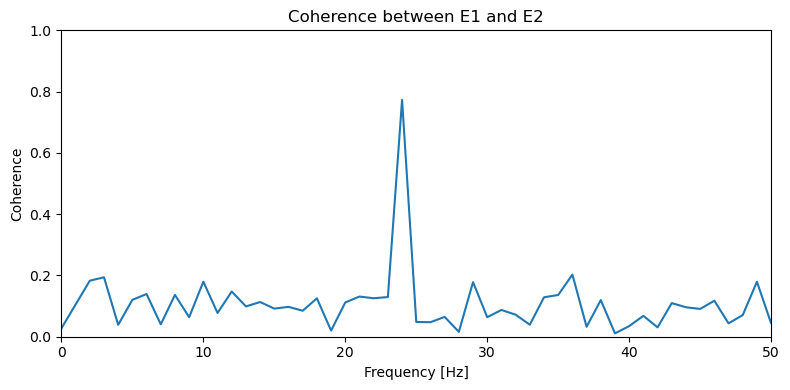

In [32]:
# Compute Sxx, Syy, Sxy for each trial, then average
Sxx = np.zeros((K, N), dtype=float)
Syy = np.zeros((K, N), dtype=float)
Sxy = np.zeros((K, N), dtype=complex)

T = t[-1]  # duration ~ 1 s

for k in range(K):
    x = E1[k, :] - E1[k, :].mean()
    y = E2[k, :] - E2[k, :].mean()
    xf = np.fft.fft(x)
    yf = np.fft.fft(y)
    Sxx[k, :] = 2 * dt**2 / T * (xf * np.conj(xf)).real
    Syy[k, :] = 2 * dt**2 / T * (yf * np.conj(yf)).real
    Sxy[k, :] = 2 * dt**2 / T * (xf * np.conj(yf))

# Keep positive frequencies
Sxx_mean = Sxx.mean(axis=0)[: N // 2 + 1]
Syy_mean = Syy.mean(axis=0)[: N // 2 + 1]
Sxy_mean = Sxy.mean(axis=0)[: N // 2 + 1]

cohr = np.abs(Sxy_mean) / (np.sqrt(Sxx_mean) * np.sqrt(Syy_mean))

df = 1.0 / T
fNQ = 1.0 / (2 * dt)
faxis = np.arange(0, fNQ + df/2, df)  # match N//2+1

plt.figure()
plt.plot(faxis, cohr)
plt.xlim([0, 50])
plt.ylim([0, 1])
plt.xlabel("Frequency [Hz]")
plt.ylabel("Coherence")
plt.title("Coherence between E1 and E2")
plt.tight_layout()
plt.show()

### Relationship between cross-covariance and coherence

The **cross-covariance** and **coherence** describe the *same* second-order
relationship between two signals, but in different domains:

- Cross-covariance $r_{xy}(\tau))$:  
  how much $(x)$ and $(y)$ co-vary as a function of **time lag** $(\tau)$.
- Coherence $(\kappa_{xy}(f))$:  
  how strongly $(x)$ and $(y)$ are phase-locked at a given **frequency** $(f)$.

Formally, the **cross-spectrum** is the Fourier transform of the
cross-covariance:

$$
S_{xy}(f)
= \mathcal{F}\{r_{xy}(\tau)\}
= \sum_{\tau} r_{xy}(\tau)\, e^{-i 2\pi f \tau}.
$$

The auto-spectra are defined similarly:

$$
S_{xx}(f) = \mathcal{F}\{r_{xx}(\tau)\}, \qquad
S_{yy}(f) = \mathcal{F}\{r_{yy}(\tau)\}.
$$

Coherence is then obtained by **normalizing** the cross-spectrum:

$$
\kappa_{xy}(f)
= \frac{|S_{xy}(f)|}
       {\sqrt{S_{xx}(f)}\sqrt{S_{yy}(f)}}.
$$

So you can think of it like this:

- The **cross-covariance** tells you:  
  “How does $(y)$ tend to look **a bit earlier or later** than $(x)$?”
- The **cross-spectrum** is the **frequency decomposition** of that same
  structure.
- The **coherence** is the **normalized strength** of that cross-spectral
  coupling at each frequency.

In our data, the cross-covariance shows an oscillatory component around 8 Hz,
but this does **not** produce a peak in coherence.  
This is because, although both electrodes exhibit 8 Hz activity, their **phase
relationship varies randomly across trials**. Cross-covariance is averaged in
the time domain and still reflects shared rhythmic structure, even when the
phase alignment is inconsistent.  

Coherence, in contrast, requires **consistent phase differences** across trials.
Random trial-to-trial phase shifts at 8 Hz suppress the coherence estimate, so no
coherence peak appears at that frequency.

Only at 24 Hz—where the phase relationship *is* stable across trials—do we see a
strong peak in coherence. To visualize this relationship, let's plot the *phase diffrerence distributions* at both frequencies.

### Phase difference distributions at 8 Hz and 24 Hz

From the coherence and spectrum, we suspect:

- strong oscillations at 8 Hz,
- strong **coherence** particularly at 24 Hz.

We compute the **cross-spectrum per trial** and extract the phase at:
- 8 Hz (index `j8`),
- 24 Hz (index `j24`),

and then plot the phase difference distributions on a polar plot.


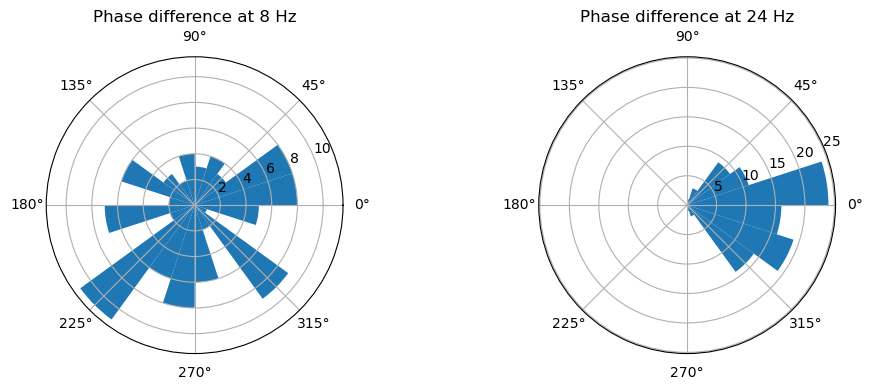

In [33]:
# Frequency axis (same as before)
faxis = np.arange(0, fNQ + df/2, df)

j8 = np.argmin(np.abs(faxis - 8.0))
j24 = np.argmin(np.abs(faxis - 24.0))

phi8 = np.zeros(K)
phi24 = np.zeros(K)

for k in range(K):
    xf = np.fft.fft(E1[k, :])
    yf = np.fft.fft(E2[k, :])
    Sxy_k = xf * np.conj(yf)
    phi8[k] = np.angle(Sxy_k[j8])  #the function angle extracts the phase difference between signals
    phi24[k] = np.angle(Sxy_k[j24])

# Polar histograms
nbins = 20
bins = np.linspace(-np.pi, np.pi, nbins + 1)

fig, axes = plt.subplots(1, 2, subplot_kw={"projection": "polar"}, figsize=(10, 4))

axes[0].hist(phi8, bins=bins)
axes[0].set_title(r"Phase difference at 8 Hz")

axes[1].hist(phi24, bins=bins)
axes[1].set_title(r"Phase difference at 24 Hz")

plt.tight_layout()
plt.show()

The polar plots show that phase relationships at 8 Hz are **random**, whereas at
24 Hz they are **highly consistent** across trials. Let's analyze this result by comparing it with the trial-averaged spectrum, the coherence, and the cross-covariance. 

![comparison cartoon](chapter5_Data/comparison.png)

**Important caution:**  
> A large oscillatory amplitude does **not** imply large coherence.  
Two signals can have strong power at the same frequency yet remain **uncoupled**
if their phases vary unpredictably.

In the cross-covariance, the strong but unaligned 8 Hz rhythm masks the more
subtle 24 Hz co-fluctuation, making it difficult to detect in the time domain.
Coherence overcomes this problem because it is **normalized by power** and
depends only on the **consistency of phase differences**, allowing the 24 Hz
interaction to emerge clearly.

## Part 2 – Spike–LFP Coupling

### Load spike–LFP data and visualize

In the second part of the tutorial, we analyze **simultaneous LFP and spike
recordings** from the hippocampus of a rat performing a navigation and
decision-making task. Your collaborator implanted a hippocampal electrode and
recorded both the **local field potential (LFP)** and the **spiking activity of a
single neuron**. The goal is to understand how these two scales of neural
activity relate.

Based on prior work, your collaborator hypothesizes that the **rhythmic structure
of the LFP modulates the probability of the neuron firing**, particularly within
specific frequency bands associated with hippocampal processing.

You are provided with **1000 trials**, each **1 second** long, sampled at **1000 Hz**,
containing perfectly aligned LFP and spike data for detailed analysis.

The data structure:

- `y`: LFP (trials × time),
- `n`: spikes as a binary matrix (trials × time, 1 = spike, 0 = no spike),
- `t`: time vector.

We visualize a single trial: an LFP trace with spikes marked.

In [2]:
base_dir = Path().resolve()

data_file = base_dir / "chapter11_Data" / "Ch11-spikes-LFP-1.mat"
data_sfl = loadmat(data_file)
y = data_sfl["y"]   # LFP, shape: (trials, samples)
n = data_sfl["n"]   # spikes, 0/1
t_s = data_sfl["t"].ravel()

dt_s = t_s[1] - t_s[0]
fs_s = 1.0 / dt_s
K_s  = y.shape[0]
N_s  = y.shape[1]

print(f"LFP shape: {y.shape}, spikes shape: {n.shape}, fs = {fs_s:.1f} Hz")

LFP shape: (100, 1000), spikes shape: (100, 1000), fs = 1000.0 Hz


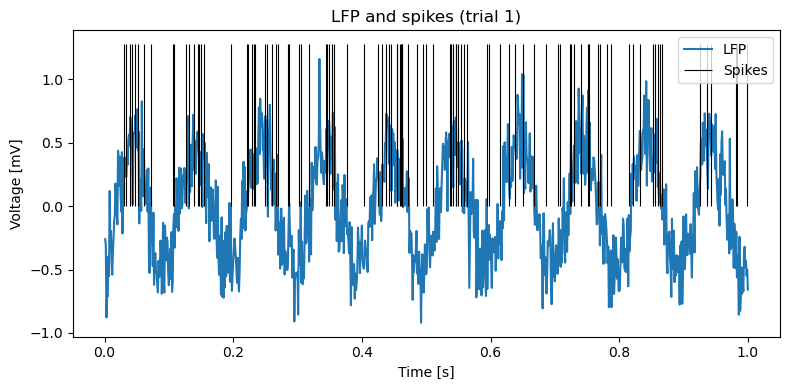

In [3]:
trial_idx = 0
lfp = y[trial_idx, :]
spikes = n[trial_idx, :]

plt.figure()
plt.plot(t_s, lfp, label="LFP")
plt.vlines(t_s[spikes == 1], ymin=0, ymax=1.1 * lfp.max(), color="k", linewidth=0.8, label="Spikes")
plt.xlabel("Time [s]")
plt.ylabel("Voltage [mV]")
plt.title(f"LFP and spikes (trial {trial_idx+1})")
plt.legend()
plt.tight_layout()
plt.show()

### Spike-triggered average (STA)

For each spike, we extract a short LFP window around it and average across spikes
(and possibly across trials). The STA shows how the LFP is organized around spike times.

Steps:

1. Choose a window (e.g., ±100 ms).
2. For each trial, find spike indices.
3. For each spike, as long as the window fits, extract the LFP snippet.
4. Average across spikes (and trials).


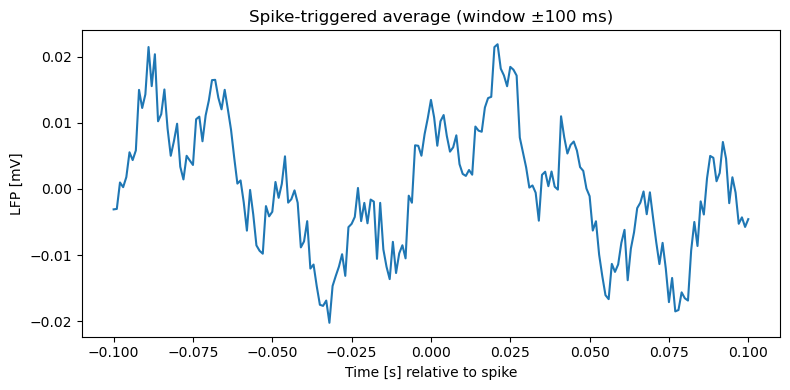

In [4]:
win_ms = 100  # window in ms
win = int(win_ms / 1000.0 / dt_s)   # window in samples

sta_all = []

for k in range(K_s):
    lfp_k = y[k, :]
    spikes_k = np.where(n[k, :] == 1)[0]
    for idx in spikes_k:
        if (idx > win) and (idx + win < N_s):
            snippet = lfp_k[idx - win : idx + win + 1]
            sta_all.append(snippet)

sta_all = np.array(sta_all)
sta_mean = sta_all.mean(axis=0)
t_win = np.arange(-win, win + 1) * dt_s

plt.figure()
plt.plot(t_win, sta_mean)
plt.xlabel("Time [s] relative to spike")
plt.ylabel("LFP [mV]")
plt.title(f"Spike-triggered average (window ±{win_ms} ms)")
plt.tight_layout()
plt.show()

### Field-triggered average (FTA) via phase sorting

The STA did not reveal strong locking in the time domain.  
Instead, we now organize spikes by the **phase** of a band-limited LFP, using:

1. Band-pass filter the LFP (e.g. 9–11 Hz or 43–47 Hz) with an FIR filter (`firwin` + `filtfilt`),
2. Compute the analytic signal via the Hilbert transform,
3. Extract instantaneous phase,
4. Sort spike train according to phase, and average across trials,
5. Plot spike probability as a function of phase.

Let's take a moment to discuss the **Hilbert transform**.

### The Hilbert transform and instantaneous phase (intuitive explanation)

When we talk about **“phase of the LFP”** at each time point, we are really asking:
> *Where are we in the cycle of the ongoing oscillation right now?  
> (near the peak, the trough, the rising zero-crossing, etc.)*

The **Hilbert transform** is a mathematical tool that helps us answer exactly that.

---

#### 1. From real signal to analytic signal

We start with a real-valued signal $(x(t))$, e.g. a band-pass filtered LFP.

The Hilbert transform $( \mathcal{H}\{x(t)\} )$ builds a second signal that is
like a **quadrature version** of $(x(t))$ (shifted by 90° in phase).

We then combine them into the **analytic signal**:

$$
z(t) = x(t) + i\,\mathcal{H}\{x(t)\}.
$$

This $(z(t))$ is complex-valued and can be written in polar form:

$$
z(t) = A(t) e^{i \phi(t)},
$$

where:

- $(A(t))$ is the **instantaneous amplitude** (envelope),
- $(\phi(t))$ is the **instantaneous phase**.

The 90° shift helps because:

- With only one signal $(x(t))$, you cannot define an angle in the plane.
- With $(x(t))$ and its quadrature copy $(q(t))$, you have a 2D vector
  $((x(t), q(t)))$.
- The **direction** of this vector is exactly the **instantaneous phase** of the
  underlying oscillation.

In other words:

> The Hilbert transform creates a second, phase-shifted version of the signal so
> that at each time point we can represent the oscillation as a rotating vector
> in the complex plane, whose angle is the instantaneous phase.

---

#### 2. Instantaneous amplitude and phase

From the analytic signal:

- Instantaneous amplitude:
  $$
  A(t) = |z(t)| = \sqrt{x(t)^2 + \mathcal{H}\{x(t)\}^2}
  $$
- Instantaneous phase:
  $$
  \phi(t) = \arg\big(z(t)\big) = \arctan2\left(\mathcal{H}\{x(t)\},\, x(t)\right).
  $$

So, at each time point, we get:

- **how strong** the oscillation is → $(A(t))$,
- **where in the cycle** we are → $(\phi(t))$.

---

#### 3. Why we use it here

In our spike–LFP analysis, we:

1. **Band-pass filter** the LFP in a frequency band of interest (e.g. 9–11 Hz or 43–47 Hz),
2. Apply the **Hilbert transform** to obtain the analytic signal,
3. Extract the **instantaneous phase** $(\phi(t))$,
4. Ask:  
   > *At which phases of the LFP does the neuron tend to spike?*

This allows us to test whether spikes are **phase locked** to an ongoing rhythm, rather than just time-locked to an external event.

In [5]:
def field_triggered_average(y, n, t, f_band, filt_order=100):
    """Compute FTA: average spike train as a function of LFP phase in a given band."""
    dt = t[1] - t[0]
    fs = 1.0 / dt
    fNQ = fs / 2.0

    Wn = [f_band[0] / fNQ, f_band[1] / fNQ]
    b = firwin(filt_order, Wn, pass_zero=False)

    K, N = y.shape
    FTA = np.zeros((K, N))

    for k in range(K):
        Vlo = filtfilt(b, 1.0, y[k, :])
        phi = np.angle(hilbert(Vlo))
        # sort spikes by phase
        sort_idx = np.argsort(phi)
        FTA[k, :] = n[k, sort_idx]

    FTA_mean = FTA.mean(axis=0)
    phases = np.linspace(-np.pi, np.pi, N)

    return phases, FTA_mean

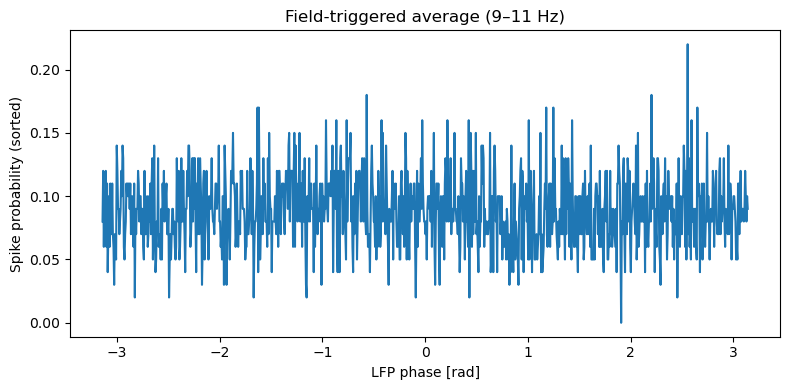

In [6]:
# 9–11 Hz
phases_9_11, FTA_9_11 = field_triggered_average(y, n, t_s, [9, 11])

plt.figure()
plt.plot(phases_9_11, FTA_9_11)
plt.xlabel("LFP phase [rad]")
plt.ylabel("Spike probability (sorted)")
plt.title("Field-triggered average (9–11 Hz)")
plt.tight_layout()
plt.show()

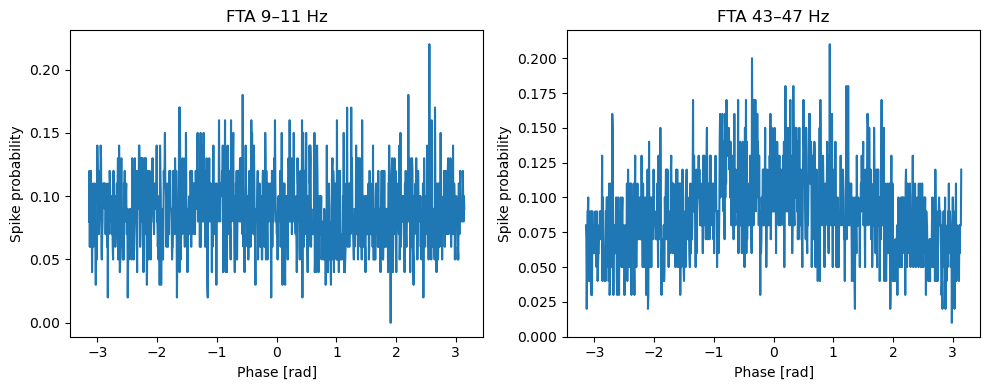

In [7]:
# 43–47 Hz
phases_43_47, FTA_43_47 = field_triggered_average(y, n, t_s, [43, 47])

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(phases_9_11, FTA_9_11)
plt.xlabel("Phase [rad]")
plt.ylabel("Spike probability")
plt.title("FTA 9–11 Hz")

plt.subplot(1, 2, 2)
plt.plot(phases_43_47, FTA_43_47)
plt.xlabel("Phase [rad]")
plt.ylabel("Spike probability")
plt.title("FTA 43–47 Hz")

plt.tight_layout()
plt.show()

### Spike–field coherence (simple FFT-based version)

We now compute the coherence between:

- continuous LFP $(y(t))$,
- binary spike train $(n(t))$.

Mathematically, this is analogous to LFP–LFP coherence, but one signal is a point process.

We define:

$$
C_{ny}(f) = \frac{|\langle S_{ny}(f)\rangle|}
{\sqrt{\langle S_{nn}(f)\rangle} \sqrt{\langle S_{yy}(f)\rangle}}
$$

where $(S_{ny})$ is the cross-spectrum between spikes and field.


In [8]:
def spike_field_coherence(y, n, t):
    """Compute spike-field coherence using simple FFT-based spectra."""
    dt = t[1] - t[0]
    T = t[-1]
    K, N = y.shape

    Syy = np.zeros((K, N), dtype=float)
    Snn = np.zeros((K, N), dtype=float)
    Sny = np.zeros((K, N), dtype=complex)

    for k in range(K):
        yk = y[k, :] - y[k, :].mean()
        nk = n[k, :] - n[k, :].mean()  # optional mean removal
        Yk = np.fft.fft(yk)
        Nk = np.fft.fft(nk)
        Syy[k, :] = 2 * dt**2 / T * (Yk * np.conj(Yk)).real
        Snn[k, :] = 2 * dt**2 / T * (Nk * np.conj(Nk)).real
        Sny[k, :] = 2 * dt**2 / T * (Nk * np.conj(Yk))

    Syy_mean = Syy.mean(axis=0)
    Snn_mean = Snn.mean(axis=0)
    Sny_mean = Sny.mean(axis=0)

    # Positive frequencies only
    Syy_mean = Syy_mean[: N // 2 + 1]
    Snn_mean = Snn_mean[: N // 2 + 1]
    Sny_mean = Sny_mean[: N // 2 + 1]

    Cny = np.abs(Sny_mean) / (np.sqrt(Snn_mean) * np.sqrt(Syy_mean))

    df = 1.0 / T
    fNQ = 1.0 / (2 * dt)
    faxis = np.arange(0, fNQ + df/2, df)

    return faxis, Cny, Syy_mean, Snn_mean

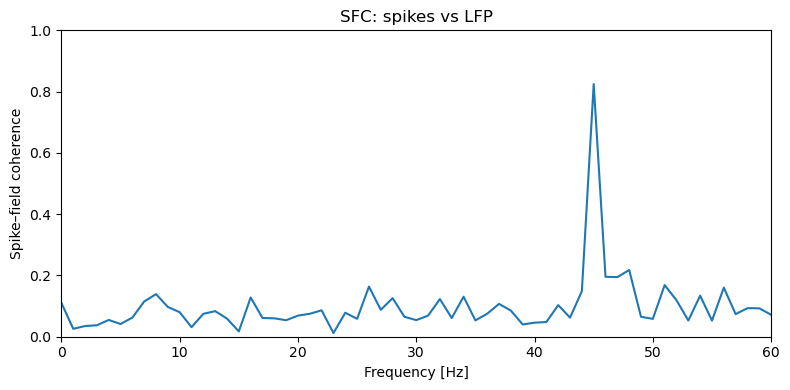

In [25]:
faxis_sfc, Cny, Syy_mean, Snn_mean = spike_field_coherence(y, n, t_s)

plt.figure()
plt.plot(faxis_sfc, Cny)
plt.xlim([0, 60])
plt.ylim([0, 1])
plt.xlabel("Frequency [Hz]")
plt.ylabel("Spike–field coherence")
plt.title("SFC: spikes vs LFP")
plt.tight_layout()
plt.show()

### Why spikes show rhythms at 10 Hz and 40–50 Hz while coherence appears only at 40–50 Hz

In these hippocampal recordings, the LFP is dominated by a **10 Hz oscillation**
(the theta rhythm). Spike trains, however, often show two rhythmic components:

1. a slow modulation around **~10 Hz** (theta),
2. a faster rhythmicity around **~40–50 Hz** (gamma).

At first glance this suggests that the neuron “responds” to both rhythms.  
But coherence tells a more nuanced story.

#### LFP oscillates at 10 Hz  
The field potential reflects population-level synaptic activity, which in this
case is clearly theta-dominated. The LFP has little power at 40–50 Hz.

#### Spikes fire rhythmically at 10 Hz *and* 40–50 Hz  
The neuron discharges:
- more often at certain **theta phases** (slow modulation), and  
- with a faster internal “clock” at **gamma frequency**.

This is common in hippocampal circuits, where gamma tends to “ride on top” of
theta and organizes spike timing within each theta cycle.

#### Why coherence only shows a strong peak at 40–50 Hz  
Coherence captures **phase locking**, not shared power.

Even though the LFP has no strong gamma power, the **gamma-aligned firing of the
neuron occurs at consistent phases of the 10 Hz cycle**.  
This creates a reliable spike–LFP phase relationship in the **40–50 Hz band**,
where the spike timing is most regular.

In contrast:

- The 10 Hz LFP oscillation is strong,  
- But **the spike timing within the theta cycle is not consistent enough across
  trials** to create a stable phase relationship.

So coherence at 10 Hz remains low.

#### The key idea

> A neuron can fire rhythmically at multiple frequencies, but only the frequency
> at which spikes show **consistent phase locking** to the LFP generates a
> coherence peak.

Here:
- spikes “feel” both theta and gamma,
- but only the **gamma-timed** firing is **phase-consistent** with respect to
  the theta-modulated LFP,
- leading to high coherence around **40–50 Hz**, not at 10 Hz.

This explains why spike autocorrelation reveals both slow and fast rhythms,  
while coherence isolates the **frequency band where coupling is reliable**.

The figure below shows these differences:

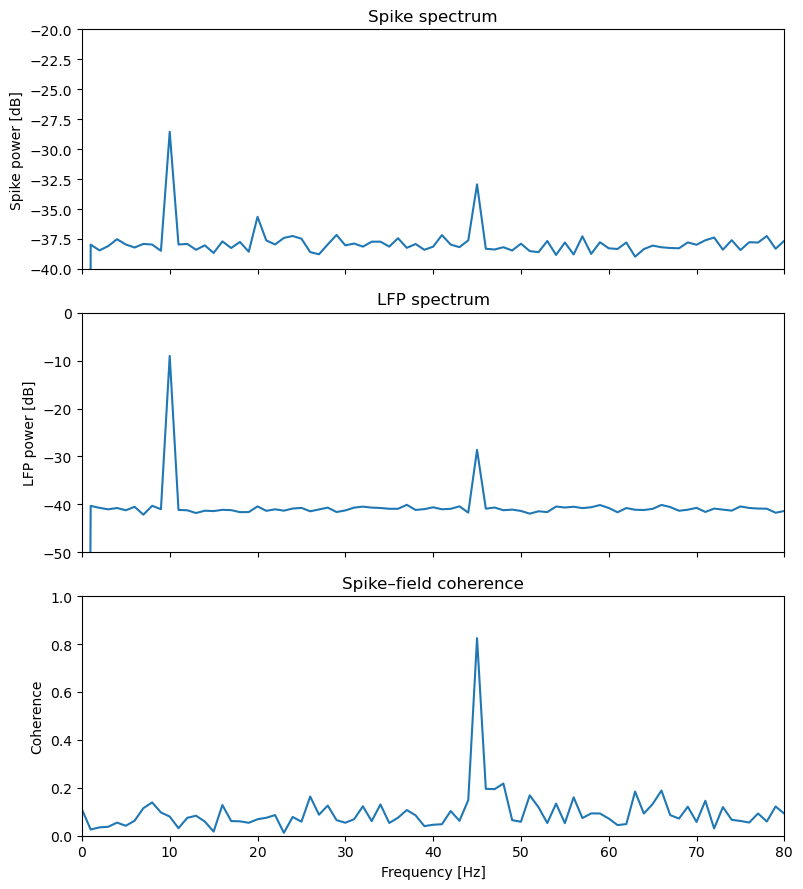

In [26]:
def spectrum(x, t, use_hann=True):
    """
    Compute one-sided power spectrum of a single trial x given time vector t.
    Returns Sxx (real-valued) aligned with rfft frequencies.
    """
    dt = t[1] - t[0]
    T = len(t) * dt
    x0 = x - x.mean()

    if use_hann:
        window = np.hanning(len(x))
        xw = window * x0
    else:
        xw = x0

    xf = np.fft.rfft(xw)
    Sxx = 2 * (dt**2) / T * (xf * np.conj(xf))
    return Sxx.real

# Sampling parameters
dt = t_s[1] - t_s[0]
N = len(t_s)
K = y.shape[0]

# 1) Spike spectrum (treat spikes as 0/1 time series)
Snn_trials = np.array([
    spectrum(n[k, :].astype(float), t_s, use_hann=False)
    for k in range(K)
])
Snn_mean = Snn_trials.mean(axis=0)

# 2) LFP spectrum
Syy_trials = np.array([
    spectrum(y[k, :], t_s, use_hann=False)
    for k in range(K)
])
Syy_mean = Syy_trials.mean(axis=0)

freqs = np.fft.rfftfreq(N, d=dt)

# 3) Spike–field coherence
faxis_sfc, Cny, _, _ = spike_field_coherence(y, n, t_s)

# ---- Plot: three panels ----
fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)

# Spike spectrum
axes[0].plot(freqs, 10 * np.log10(Snn_mean))
axes[0].set_xlim(0, 80)
axes[0].set_ylim(-40, -20)
axes[0].set_ylabel("Spike power [dB]")
axes[0].set_title("Spike spectrum")

# LFP spectrum
axes[1].plot(freqs, 10 * np.log10(Syy_mean))
axes[1].set_xlim(0, 80)
axes[1].set_ylim(-50, 0)
axes[1].set_ylabel("LFP power [dB]")
axes[1].set_title("LFP spectrum")

# Spike–field coherence
axes[2].plot(faxis_sfc, Cny)
axes[2].set_xlim(0, 80)
axes[2].set_ylim(0, 1)
axes[2].set_xlabel("Frequency [Hz]")
axes[2].set_ylabel("Coherence")
axes[2].set_title("Spike–field coherence")

plt.tight_layout()
plt.show()




### Differences between LFP–LFP coherence and spike–field coherence (SFC)

Although LFP–LFP coherence and spike–field coherence are computed with similar
mathematical tools (cross-spectra, normalization, phase consistency), the **nature
of the input signals is fundamentally different**, and this leads to important
interpretational differences.

#### 1. LFP–LFP coherence: continuous × continuous
Both LFPs are **continuous-valued signals**.  
They have well-defined amplitudes at every time point, and their spectra reflect
the distribution of power across frequencies.  
Coherence here measures:

> how consistently two *continuous rhythms* maintain a stable phase relationship.

Because both inputs are continuous, coherence is influenced by:
- the strength of rhythmic activity (power),
- trial-to-trial phase alignment,
- shared noise or common input.

#### 2. Spike–field coherence: point process × continuous signal
Spikes are **point events**, not continuous signals.  
A spike train is essentially a sequence of time stamps (or a 0/1 sequence if
sampled).  
This introduces two important consequences:

**(a) The spectrum of a spike train reflects *timing regularity*, not amplitude.**  
A spike train has no “amplitude” in the usual sense—its spectral peaks arise from
regularities in **when** spikes occur, not from a waveform.

**(b) SFC measures phase locking, not power relationships.**  
Spike–field coherence tells us:

> how consistently spikes occur at a particular **phase** of an LFP oscillation.

If a neuron fires preferentially at a certain phase (e.g., LFP trough), SFC is
high—even if spike rate is low.

If spikes occur randomly with respect to LFP phase, SFC is low—even if the LFP
has strong rhythmic power.

#### 3. Sensitivity to spike rate (see below)
Because spikes are sparse events, SFC is strongly affected by **how many spikes**
you have:
- fewer spikes → noisier estimates → reduced coherence,
- more spikes → more reliable phase statistics.

LFP–LFP coherence does *not* suffer from this issue since both signals have
power at every time sample.

In sum:
- **LFP–LFP coherence** measures the consistency of phase relationships between
  *two continuous rhythms*.
- **Spike–field coherence** measures whether *discrete spike times* occur at
  preferred phases of a continuous LFP oscillation.

Thus, SFC is inherently about **phase locking of point events to a field**, not
about amplitude correlations between two waveforms.

### Impact of LFP amplitude on SFC

We now scale the LFP by a constant factor and recompute SFC.
The expectation is:

> Changing the **amplitude** of the LFP does not change SFC,  
> because SFC depends mainly on **phase consistency**, not absolute power.

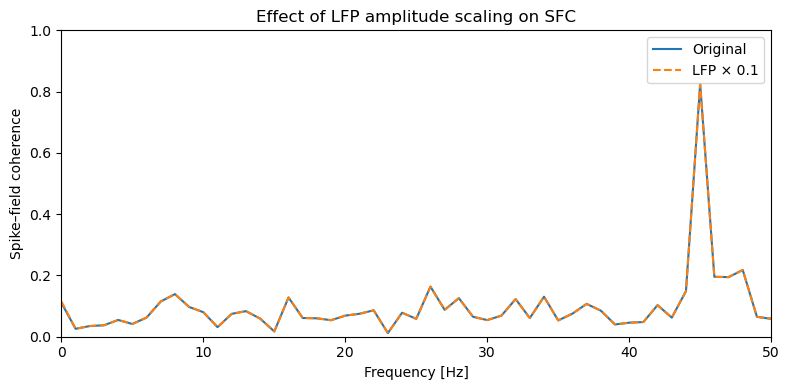

In [22]:
y_scaled = 0.1 * y
faxis_sfc_scaled, Cny_scaled, _, _ = spike_field_coherence(y_scaled, n, t_s)

plt.figure()
plt.plot(faxis_sfc, Cny, label="Original")
plt.plot(faxis_sfc_scaled, Cny_scaled, label="LFP × 0.1", linestyle="--")
plt.xlim([0, 50])
plt.ylim([0, 1])
plt.xlabel("Frequency [Hz]")
plt.ylabel("Spike–field coherence")
plt.title("Effect of LFP amplitude scaling on SFC")
plt.legend()
plt.tight_layout()
plt.show()

### Impact of firing rate (thinning spikes) on SFC

We now **thin** the spike train by randomly removing spikes (e.g. keeping 50%).
We recompute SFC and compare.

Unlike LFP amplitude, **firing rate does affect SFC**:  
lower spike counts lead to reduced coherence estimates, even if spike–phase locking is unchanged.


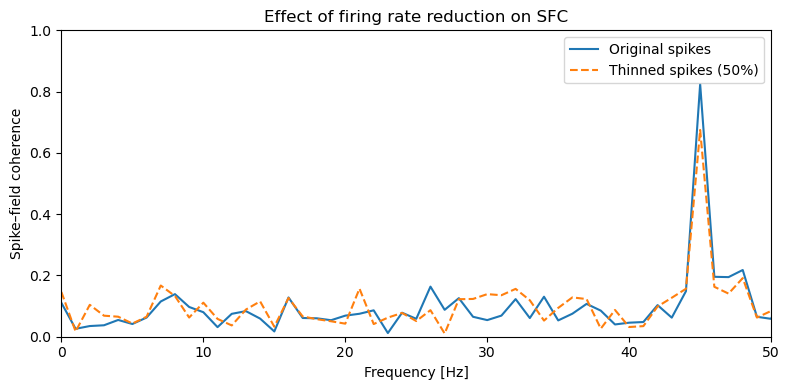

In [23]:
# Copy spikes and thin them
thinning_factor = 0.5  # remove 50% of spikes
n_thinned = n.copy()

rng = np.random.default_rng(seed=42)

for k in range(K_s):
    spike_idx = np.where(n_thinned[k, :] == 1)[0]
    n_spikes = len(spike_idx)
    if n_spikes == 0:
        continue
    perm = rng.permutation(spike_idx)
    n_remove = int(np.floor(thinning_factor * n_spikes))
    n_thinned[k, perm[: n_remove]] = 0

# Recompute SFC with thinned spikes
faxis_sfc_thin, Cny_thin, _, _ = spike_field_coherence(y, n_thinned, t_s)

plt.figure()
plt.plot(faxis_sfc, Cny, label="Original spikes")
plt.plot(faxis_sfc_thin, Cny_thin, label="Thinned spikes (50%)", linestyle="--")
plt.xlim([0, 50])
plt.ylim([0, 1])
plt.xlabel("Frequency [Hz]")
plt.ylabel("Spike–field coherence")
plt.title("Effect of firing rate reduction on SFC")
plt.legend()
plt.tight_layout()
plt.show()

## Summary

- We analyzed ECoG signals from two electrodes and found:
  - a strong 8 Hz rhythm in the spectrum,
  - a clear 24 Hz peak in the coherence,
  - alignment of phase differences at 24 Hz but not at 8 Hz.

- We extended the analysis to multiscale spike–LFP data:
  - STA revealed no strong phase locking in the raw time domain,
  - FTA showed how spikes relate to the **phase** of band-limited LFP rhythms,
  - Spike–field coherence quantified the strength of this coupling in the frequency domain.

- We showed that:
  - SFC is robust to simple scaling of LFP amplitude,
  - but strongly affected by firing rate (spike count),
    which must be considered carefully when interpreting and comparing SFC.
